## Notebook to create a protoplanetary disk

### Initial conditions

Gas accretion onto the embryo is replaced by a subgrid model with a maximum mass limit per accretion event instead of a 0.1 AU sink

In [1]:
import numpy
from amuse.units import units, constants, nbody_system
from amuse.ext.orbital_elements import generate_binaries
from amuse.lab import Particles

In [2]:
# Generating the binary system 

M_A = 1.0788 | units.Msun
M_B = 0.9092 | units.Msun
a = 23.299 | units.au
e = 0.51947
i = 79.243 | units.deg # how it is viewed from earth, unimportant until placing a disk
long_asc_node = 205.073 | units.deg # defines how orbital plane is rotated along LoS, also unimportant
arg_per = 231.519 | units.deg # defines where periapsis lies in orbital plane, unimportant
true_an = 180 | units.deg # stars start at apastron, i.e. furthest apart
primaries, secondaries = generate_binaries(M_A, M_B, a, e, true_anomaly=true_an, G=constants.G)

alpha_cen_A = primaries[0]
alpha_cen_B = secondaries[0]

alpha_cen_A.name = "Alpha_Centauri_A"
alpha_cen_B.name = "Alpha_Centauri_B"

system = Particles()
system.add_particle(alpha_cen_A)
system.add_particle(alpha_cen_B)
system.move_to_center()

print(system)
print(alpha_cen_A.x)

                 key         mass         name           vx           vy           vz            x            y            z
                   -  1.98892e+30 * kg         none  3646245880.3572216 * m * s**-1  3646245880.3572216 * m * s**-1  3646245880.3572216 * m * s**-1  149597870691.0 * m  149597870691.0 * m  149597870691.0 * m
====================  ===========  ===========  ===========  ===========  ===========  ===========  ===========  ===========
 4375512867498599124    1.079e+00  Alpha_Centauri_A    1.564e-22    6.138e-07    0.000e+00    1.619e+01   -1.983e-15   -0.000e+00
 9112753363635515367    9.092e-01  Alpha_Centauri_B   -1.856e-22   -7.283e-07    0.000e+00   -1.921e+01    2.353e-15    0.000e+00
====================  ===========  ===========  ===========  ===========  ===========  ===========  ===========  ===========
16.1909547219 149597870691.0 * m


In [3]:
# Candidate planet is a gas giant orbiting Alpha Centauri A. We can start with a fully-formed Saturn mass planet and test orbital stability. 
# After orbital stability is established (hopefully): start with a core of 10-20 Mearth and simulate core accretion of gas to form a gas giant

# First, explore orbital stability of candidate gas giant 

M_embryo = 0.0123 | units.Mearth
a_embryo = 2 | units.au
e_embryo = 0

stars, planets = generate_binaries(M_A, M_embryo, a_embryo, e_embryo, G=constants.G)
star = stars[0]
planet = planets[0]
planet.position -= star.position # planet position relative to star 
planet.velocity -= star.velocity # planet velocity relative to star

planet.position += system[0].position # absolute position
planet.velocity += system[0].velocity # absolute velocity 

planet.name = "Alpha_Centauri_Ab"
R_acc = 0.1 | units.au
planet.radius = R_acc

system.add_particle(planet)
system.move_to_center()
print(system)
print(alpha_cen_A.x)

                 key         mass         name       radius           vx           vy           vz            x            y            z
                   -  1.98892e+30 * kg         none           au  3646245880.3572216 * m * s**-1  3646245880.3572216 * m * s**-1  3646245880.3572216 * m * s**-1  149597870691.0 * m  149597870691.0 * m  149597870691.0 * m
====================  ===========  ===========  ===========  ===========  ===========  ===========  ===========  ===========  ===========
 4375512867498599124    1.079e+00  Alpha_Centauri_A    0.000e+00    1.564e-22    6.138e-07    0.000e+00    1.619e+01   -1.983e-15   -0.000e+00
 9112753363635515367    9.092e-01  Alpha_Centauri_B    0.000e+00   -1.856e-22   -7.283e-07    0.000e+00   -1.921e+01    2.353e-15    0.000e+00
17629442761620848007    3.693e-08  Alpha_Centauri_Ab    1.000e-01    1.564e-22    6.614e-06    0.000e+00    1.819e+01   -1.983e-15    0.000e+00
====================  ===========  ===========  ===========  =========== 

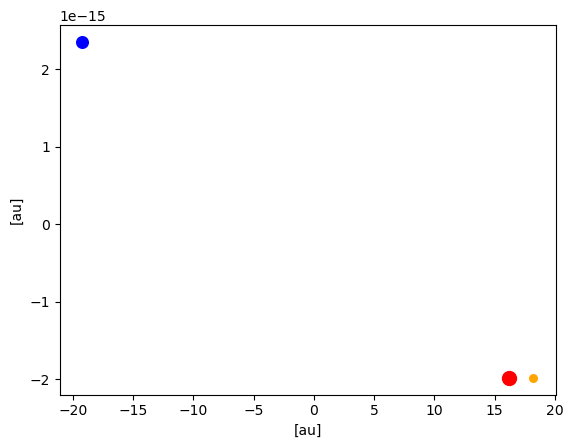

In [4]:
from amuse.plot import scatter

scatter(alpha_cen_A.x.in_(units.au), alpha_cen_A.y.in_(units.au), s=100, c='red')
scatter(alpha_cen_B.x.in_(units.au), alpha_cen_B.y.in_(units.au), s=70, c='blue')
scatter(planet.x.in_(units.au), planet.y.in_(units.au), s=30, c='orange')

In [5]:
from amuse.ext.protodisk import ProtoPlanetaryDisk

M_scale = M_A
R_scale = a
converter = nbody_system.nbody_to_si(M_scale, R_scale)
Ndisk = 1000
Rin = 0.2 | units.au
Rout = 3 | units.au
rmin = Rin/R_scale
rmax = Rout/R_scale
Mdisk = 0.001 | units.Msun
system.move_to_center()
star_A = system[system.name == "Alpha_Centauri_A"]
disk = ProtoPlanetaryDisk(
    Ndisk,
    convert_nbody=converter,
    radius_min=rmin,
    radius_max=rmax,
    q_out=10,
    discfraction=Mdisk/M_A
).result
disk.name = "disk"

disk.move_to_center()
print(disk.position.lengths().max().in_(units.au))
disk.position += star_A.position # absolute coordinates of disk 
disk.velocity += star_A.velocity # absolute velocity of disk
masses = Mdisk / float(Ndisk) # mass distributed equally 
disk.mass = masses
rho = 3.0 | (units.g / units.cm**3) # assume density of material
disk.radius = (disk.mass / (4 * rho))**(1./3.) # assign physical radius to each particle using formula
system.add_particles(disk)

print(system)


3.02249043039 au
                 key         mass         name       radius            u           vx           vy           vz            x            y            z
                   -  1.98892e+30 * kg         none           au  m**2 * s**-2  3646245880.3572216 * m * s**-1  3646245880.3572216 * m * s**-1  3646245880.3572216 * m * s**-1  149597870691.0 * m  149597870691.0 * m  149597870691.0 * m
====================  ===========  ===========  ===========  ===========  ===========  ===========  ===========  ===========  ===========  ===========
 4375512867498599124    1.079e+00  Alpha_Centauri_A    0.000e+00    0.000e+00    1.564e-22    6.138e-07    0.000e+00    1.619e+01   -1.983e-15   -0.000e+00
 9112753363635515367    9.092e-01  Alpha_Centauri_B    0.000e+00    0.000e+00   -1.856e-22   -7.283e-07    0.000e+00   -1.921e+01    2.353e-15    0.000e+00
17629442761620848007    3.693e-08  Alpha_Centauri_Ab    1.000e-01    0.000e+00    1.564e-22    6.614e-06    0.000e+00    1.819e+01   -

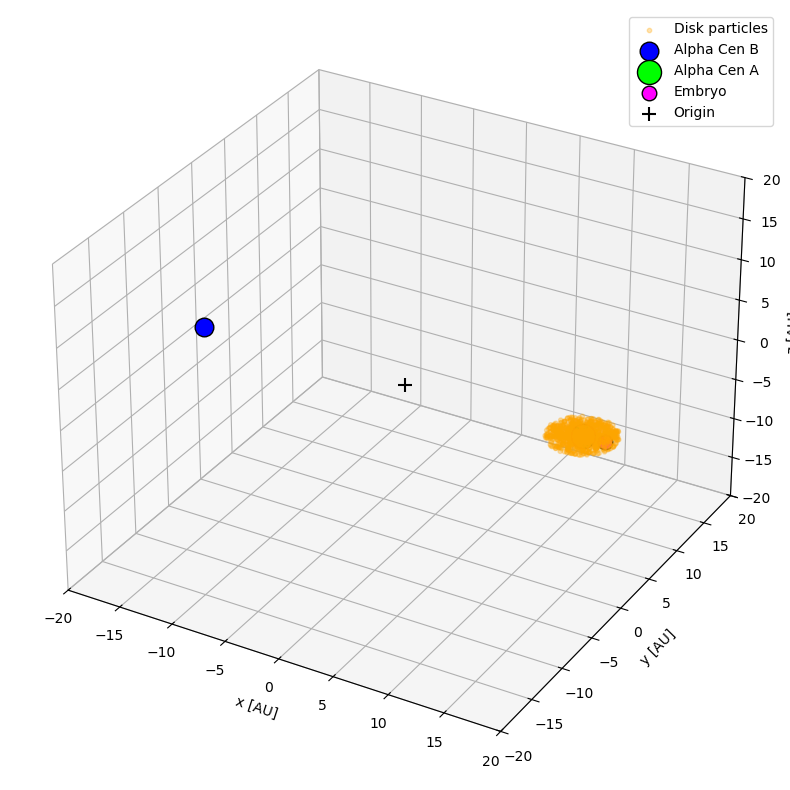

In [6]:
import matplotlib.pyplot as plt

fig = plt.figure(figsize=(8, 8))
ax = fig.add_subplot(111, projection="3d")

ax.scatter(disk.x.value_in(units.au),
           disk.y.value_in(units.au),
           disk.z.value_in(units.au),
           s=10, c="orange", alpha=0.3, label="Disk particles")

ax.scatter(alpha_cen_B.x.value_in(units.au),
           alpha_cen_B.y.value_in(units.au),
           alpha_cen_B.z.value_in(units.au),
           s=180, c="blue", edgecolors="black",
           depthshade=False, label="Alpha Cen B")

ax.scatter(alpha_cen_A.x.value_in(units.au),
           alpha_cen_A.y.value_in(units.au),
           alpha_cen_A.z.value_in(units.au),
           s=300, c="lime", edgecolors="black",
           depthshade=False, label="Alpha Cen A")

ax.scatter(planet.x.value_in(units.au),
           planet.y.value_in(units.au),
           planet.z.value_in(units.au),
           s=110, c="magenta", edgecolors="black",
           depthshade=False, label="Embryo")

ax.scatter(0, 0, 0, color="black", marker="+", s=100, label="Origin")
ax.set_xlim(-20, 20)
ax.set_ylim(-20, 20)
ax.set_zlim(-20, 20)

ax.set_xlabel("x [AU]")
ax.set_ylabel("y [AU]")
ax.set_zlabel("z [AU]")
ax.legend()
plt.tight_layout()
plt.show()

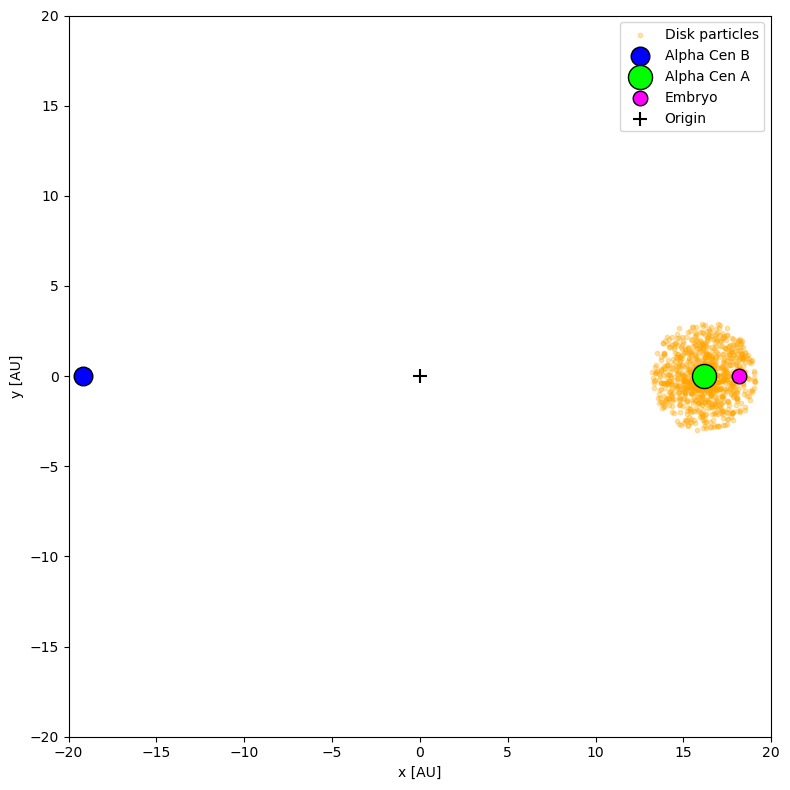

In [7]:
import matplotlib.pyplot as plt

fig = plt.figure(figsize=(8, 8))
ax = fig.add_subplot()

ax.scatter(disk.x.value_in(units.au),
           disk.y.value_in(units.au),
           s=10, c="orange", alpha=0.3, label="Disk particles")

ax.scatter(alpha_cen_B.x.value_in(units.au),
           alpha_cen_B.y.value_in(units.au),
           s=180, c="blue", edgecolors="black",
            label="Alpha Cen B")

ax.scatter(alpha_cen_A.x.value_in(units.au),
           alpha_cen_A.y.value_in(units.au),
           s=300, c="lime", edgecolors="black",
            label="Alpha Cen A")

ax.scatter(planet.x.value_in(units.au),
           planet.y.value_in(units.au),
           s=110, c="magenta", edgecolors="black",
          label="Embryo")

ax.scatter(0, 0, color="black", marker="+", s=100, label="Origin")
ax.set_xlim(-20, 20)
ax.set_ylim(-20, 20)

ax.set_xlabel("x [AU]")
ax.set_ylabel("y [AU]")
ax.legend()
plt.tight_layout()
plt.show()

## Coupled hydrodynamics + gravity

This section **replaces the original gravity-only evolution and accretion cells**. Run the setup cells above, then these cells. The original `system` includes disk particles, but the gravity solver must receive **only the two stars and embryo**; Fi receives the gas. Fi supplies gas self-gravity and hydrodynamics. Bridge exchanges the mutual gravitational forces.

In [8]:
import numpy as np
import matplotlib.pyplot as plt
from amuse.community.huayno.interface import Huayno
from amuse.community.fi.interface import Fi
from amuse.couple.bridge import Bridge
from amuse.datamodel import Particles
from amuse.units import units, constants

# Using the pre-existing initial conditions
# Disk particles belong exclusively to Fi, not to Huayno.
bodies = system[system.name != "disk"].copy()
gas_initial = system[system.name == "disk"].copy()
assert len(bodies) == 3
assert len(gas_initial) == Ndisk

# Record immutable AMUSE particle keys before transferring bodies to Huayno.
key_A = bodies[bodies.name == "Alpha_Centauri_A"][0].key
key_B = bodies[bodies.name == "Alpha_Centauri_B"][0].key
key_P = bodies[bodies.name == "Alpha_Centauri_Ab"][0].key

def get_particle(particles, key):
    """Identify a solver particle by its stable AMUSE key, not a custom name."""
    matches = particles[particles.key == key]
    if len(matches) != 1:
        raise RuntimeError(f"Expected exactly one particle with key {key}, got {len(matches)}")
    return matches[0]

# ProtoPlanetaryDisk normally supplies thermal energy (u).
# Check explicitly instead of silently assigning a physically arbitrary value.
if 'u' not in gas_initial.get_attribute_names_defined_in_store():
    raise RuntimeError("Disk has no specific internal energy 'u'. Initialize a physically justified temperature profile before using Fi.")

# Replace the solid-body radius from the original setup: SPH gas radii
# are NOT the radii of solid grains. Fi determines smoothing lengths.
gas_initial.radius = 0 | units.au

# The original converter uses binary separation as its length scale.
# It is consistent for both gravity and hydro solvers.
gravity = Huayno(converter)
gravity.particles.add_particles(bodies)

hydro = Fi(converter)
# Explicit Fi timestep is required for reliable advancement on this setup.
hydro.parameters.timestep = 0.0002 | units.yr
hydro.gas_particles.add_particles(gas_initial)

# Bridge kicks each solver with the gravity field of the other.
# Do NOT also add gas to Huayno, or gas gravity will be double counted.
bridge = Bridge(use_threading=False)
bridge.add_system(gravity, (hydro,))
bridge.add_system(hydro, (gravity,))

# Bridge timestep must resolve the innermost orbital period.
dt_bridge = 0.002 | units.yr
bridge.timestep = dt_bridge

# Refresh snapshots from the solver sets, including after accretion.
def synchronize_snapshots():
    global body_state, gas_state
    body_state = gravity.particles.copy()
    gas_state = hydro.gas_particles.copy()

synchronize_snapshots()

print('Gravity particles:', len(gravity.particles))
print('Gas particles:', len(hydro.gas_particles))


Gravity particles: 3
Gas particles: 1000


### Hydrodynamically informed, partial-mass accretion (1,000 SPH particles)

The original 0.1 AU whole-particle sink is replaced with an **experimental subgrid** prescription. Fi supplies gas density, internal energy and velocities; an adaptive kernel estimates local conditions around the embryo. A Bondi–Hoyle-like rate is capped by a Hill-area supply estimate and by the available SPH particle mass. A small fraction of nearby particle masses is transferred, conserving total mass and linear momentum in the transfer. **This does not resolve the Hill sphere, gas capture, shocks or a circumplanetary disk - more gas particles needed later.** 

The kernel uses the nearest 32 particles, so its size is measured and reported rather than mistaken for the Hill radius. The rate is updated every `output_dt=0.02 yr`. No gas particle is deleted by this prescription.

In [9]:
# Subgrid accretion controls. All three caps are deliberately conservative.
accretion_neighbors = 32       # SPH-scale estimate, NOT a resolved Hill sphere
max_fraction_per_update = 0.01 # at most 1% of any particle's mass per update
accretion_efficiency = 0.1    # uncertain dimensionless efficiency
minimum_kernel_radius = 0.2 | units.au

# Fi's ideal-gas adiabatic sound speed from specific internal energy.
# This matches the current non-isothermal Fi setup; gamma is read from Fi.
def partial_hydro_accretion(dt):
    embryo = get_particle(gravity.particles, key_P)
    star = get_particle(gravity.particles, key_A)
    gas = hydro.gas_particles
    if len(gas) == 0:
        return dict(dm=0.0, n_affected=0, hill_au=np.nan,
                    kernel_au=np.nan, rho_kg_m3=np.nan)

    # Numerical SI arrays avoid AMUSE quantity broadcasting and mixing units.
    pos = gas.position.value_in(units.m)
    vel = gas.velocity.value_in(units.m / units.s)
    masses = gas.mass.value_in(units.kg)
    gp = embryo.position.value_in(units.m)
    gv = embryo.velocity.value_in(units.m / units.s)
    sp = star.position.value_in(units.m)
    mp = embryo.mass.value_in(units.kg)
    ms = star.mass.value_in(units.kg)
    G = constants.G.value_in(units.m**3 / (units.kg * units.s**2))
    dt_s = dt.value_in(units.s)

    distances = np.linalg.norm(pos - gp[None, :], axis=1)
    k = min(accretion_neighbors, len(gas))
    ids = np.argpartition(distances, k - 1)[:k]
    h = max(float(distances[ids].max()), minimum_kernel_radius.value_in(units.m))
    # Gaussian smoothing of Fi-computed thermodynamic and velocity fields.
    w = np.exp(-0.5 * (distances[ids] / h)**2)
    w /= w.sum()
    rho = gas.rho.value_in(units.kg / units.m**3)[ids]
    u = gas.u.value_in(units.m**2 / units.s**2)[ids]
    gamma = float(hydro.parameters.gamma)
    cs2 = np.maximum(gamma * (gamma - 1.0) * u, 0.0)
    local_rho = float(np.dot(w, rho))
    local_cs2 = float(np.dot(w, cs2))
    local_velocity = np.sum(w[:, None] * vel[ids], axis=0)
    vrel2 = float(np.sum((local_velocity - gv)**2))
    effective_speed = np.sqrt(max(local_cs2 + vrel2, 1e-30))

    rstar = np.linalg.norm(gp - sp)
    hill = rstar * (mp / (3.0 * ms))**(1.0 / 3.0)
    # Subgrid rate: BHL-like estimate, limited by Hill-area mass flux.
    mdot_bhl = 4.0 * np.pi * G**2 * mp**2 * local_rho / effective_speed**3
    mdot_hill = np.pi * hill**2 * local_rho * effective_speed
    requested = max(0.0, accretion_efficiency * min(mdot_bhl, mdot_hill) * dt_s)

    # Distribute the transfer across nearby particles. Limit each donor to
    # 1% of its mass per update, preserving the full SPH particle population.
    capacities = max_fraction_per_update * masses[ids]
    dm_i = np.zeros(k)
    remaining = requested
    for _ in range(k + 1):
        room = capacities - dm_i
        active = room > max(1e-14 * max(requested, 1.0), 0.0)
        if not np.any(active) or remaining <= 0:
            break
        shares = remaining * w * active / np.sum(w * active)
        take = np.minimum(shares, np.maximum(room, 0.0))
        dm_i += take
        remaining -= take.sum()
    dm = float(dm_i.sum())
    if dm > 0:
        # Conserve linear momentum when transferring mass to the embryo.
        p_old = mp * gv
        p_transfer = np.sum(dm_i[:, None] * vel[ids], axis=0)
        new_mass = masses.copy()
        new_mass[ids] -= dm_i
        if np.any(new_mass <= 0):
            raise RuntimeError('Partial accretion attempted to remove all gas mass')
        gas.mass = new_mass | units.kg
        embryo.mass = (mp + dm) | units.kg
        embryo.velocity = ((p_old + p_transfer) / (mp + dm)) | (units.m / units.s)

    return dict(dm=dm / (1 | units.Mearth).value_in(units.kg),
                n_affected=int(np.count_nonzero(dm_i)),
                hill_au=hill / (1 | units.au).value_in(units.m),
                kernel_au=h / (1 | units.au).value_in(units.m),
                rho_kg_m3=local_rho)

# This is a custom mass-transfer model. Fi does NOT natively accrete
# fractional particles; changing gas.mass changes the live Fi particle set.


In [10]:
# Disk morphology and stability diagnostics (restored).
def disk_metrics():
    synchronize_snapshots()
    A = get_particle(body_state, key_A)
    P = get_particle(body_state, key_P)
    if len(gas_state) == 0:
        return dict(mdisk=0., r10=np.nan, r50=np.nan, r90=np.nan,
                    near_planet=0, x=np.array([]), y=np.array([]))
    r = (gas_state.position - A.position).lengths().value_in(units.au)
    order = np.argsort(r)
    mass = gas_state.mass.value_in(units.Msun)
    cdf = np.cumsum(mass[order]) / mass.sum()
    q = np.interp([0.1, 0.5, 0.9], cdf, r[order])
    dist_planet = (gas_state.position - P.position).lengths().value_in(units.au)
    return dict(mdisk=float(mass.sum()), r10=q[0], r50=q[1], r90=q[2],
                near_planet=int(np.sum(dist_planet < 0.2)),
                x=(gas_state.x-A.x).value_in(units.au).copy(),
                y=(gas_state.y-A.y).value_in(units.au).copy())


# Bound-gas and morphology diagnostics relative to Alpha Centauri A.
# A two-body binding proxy is used here; companion tides and pressure can
# exchange energy, so instantaneous bound fraction is NOT a permanent survival test.
def disk_stability_metrics():
    A = get_particle(gravity.particles, key_A)
    gas = hydro.gas_particles.copy()
    if len(gas) == 0:
        return dict(bound_fraction=np.nan, r90_bound=np.nan, disk_eccentricity=np.nan)
    dr = gas.position - A.position
    dv = gas.velocity - A.velocity
    r = dr.lengths()
    eps = 0.5 * dv.lengths_squared() - constants.G * A.mass / r
    bound = gas[eps < (0 | (units.m**2 / units.s**2))]
    frac = float(bound.total_mass() / gas.total_mass()) if len(bound) else 0.0
    if not len(bound):
        return dict(bound_fraction=float(frac), r90_bound=np.nan, disk_eccentricity=np.nan)
    rb = (bound.position - A.position).lengths().value_in(units.au)
    mb = bound.mass.value_in(units.Msun)
    inds = np.argsort(rb)
    cdf = np.cumsum(mb[inds]) / np.sum(mb)
    r90_bound = float(np.interp(0.9, cdf, rb[inds]))
    # Mass-weighted instantaneous osculating eccentricity (Kepler proxy).
    d = (bound.position - A.position).value_in(units.m)
    v = (bound.velocity - A.velocity).value_in(units.m / units.s)
    mu = (constants.G * A.mass).value_in(units.m**3 / units.s**2)
    h = np.cross(d, v)
    evec = np.cross(v, h) / mu - d / np.linalg.norm(d, axis=1)[:, None]
    eccentricity = float(np.average(np.linalg.norm(evec, axis=1), weights=mb))
    return dict(bound_fraction=float(frac), r90_bound=r90_bound, disk_eccentricity=eccentricity)


In [11]:
# One-year pilot; progress and accretion reported after every output.
t_end = 1.0 | units.yr
output_dt = 0.02 | units.yr
n_outputs = int(round(t_end / output_dt))
history = []
accreted_mass_total = 0.0

def save_record(t, acc=None):
    if acc is None:
        acc = dict(dm=0.0, n_affected=0, hill_au=np.nan,
                   kernel_au=np.nan, rho_kg_m3=np.nan)
    m = disk_metrics()
    P = get_particle(body_state, key_P)
    history.append(dict(t=t.value_in(units.yr),
                        embryo_mass=P.mass.value_in(units.Mearth),
                        n_gas=len(gas_state), n_accreted=acc['n_affected'],
                        dm_accreted=acc['dm'], hill_au=acc['hill_au'],
                        kernel_au=acc['kernel_au'], rho_kg_m3=acc['rho_kg_m3'],
                        **m, **disk_stability_metrics()))

save_record(0 | units.yr)
for j in range(1, n_outputs + 1):
    target = j * output_dt
    bridge.evolve_model(target)
    acc = partial_hydro_accretion(output_dt)
    accreted_mass_total += acc['dm']
    save_record(target, acc)
    h = history[-1]
    print(f"t={h['t']:.3f} yr, gas={h['n_gas']}, "
          f"embryo={h['embryo_mass']:.6g} Mearth, "
          f"dm={acc['dm']:.3e} Mearth, donors={acc['n_affected']}, "
          f"Hill={acc['hill_au']:.3e} AU, kernel={acc['kernel_au']:.3e} AU", flush=True)

print(f'Total transferred gas mass: {accreted_mass_total:.6e} Mearth')


t=0.020 yr, gas=1000, embryo=0.0123 Mearth, dm=5.424e-11 Mearth, donors=32, Hill=4.503e-03 AU, kernel=6.000e-01 AU
t=0.040 yr, gas=1000, embryo=0.0123 Mearth, dm=7.043e-11 Mearth, donors=32, Hill=4.503e-03 AU, kernel=5.950e-01 AU
t=0.060 yr, gas=1000, embryo=0.0123 Mearth, dm=6.928e-11 Mearth, donors=32, Hill=4.503e-03 AU, kernel=6.018e-01 AU
t=0.080 yr, gas=1000, embryo=0.0123 Mearth, dm=6.213e-11 Mearth, donors=32, Hill=4.503e-03 AU, kernel=5.974e-01 AU
t=0.100 yr, gas=1000, embryo=0.0123 Mearth, dm=4.424e-11 Mearth, donors=32, Hill=4.503e-03 AU, kernel=5.969e-01 AU
t=0.120 yr, gas=1000, embryo=0.0123 Mearth, dm=1.422e-12 Mearth, donors=32, Hill=4.503e-03 AU, kernel=5.877e-01 AU
t=0.140 yr, gas=1000, embryo=0.0123 Mearth, dm=7.481e-14 Mearth, donors=32, Hill=4.503e-03 AU, kernel=5.547e-01 AU
t=0.160 yr, gas=1000, embryo=0.0123 Mearth, dm=9.200e-14 Mearth, donors=32, Hill=4.503e-03 AU, kernel=5.087e-01 AU
t=0.180 yr, gas=1000, embryo=0.0123 Mearth, dm=8.236e-14 Mearth, donors=32, Hill

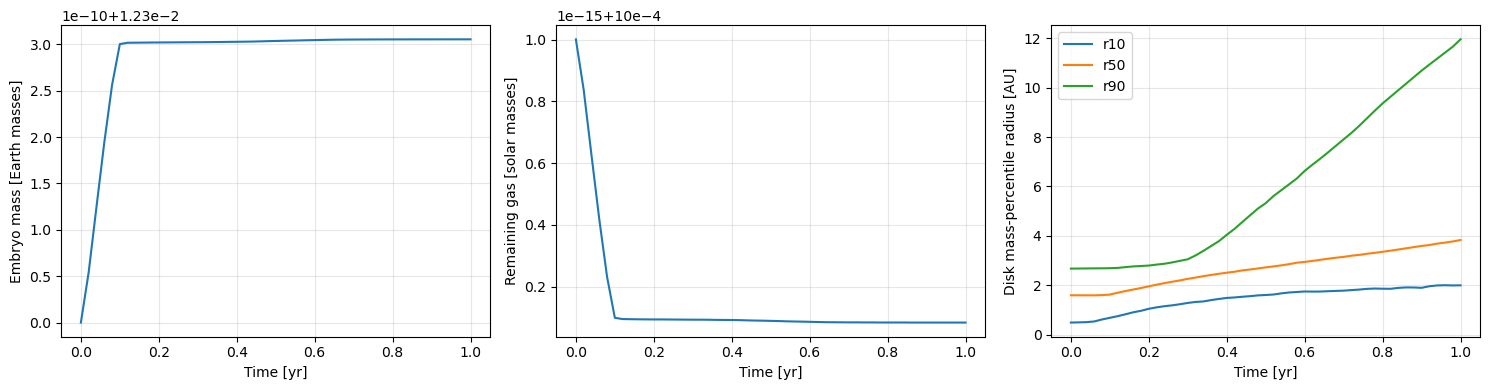

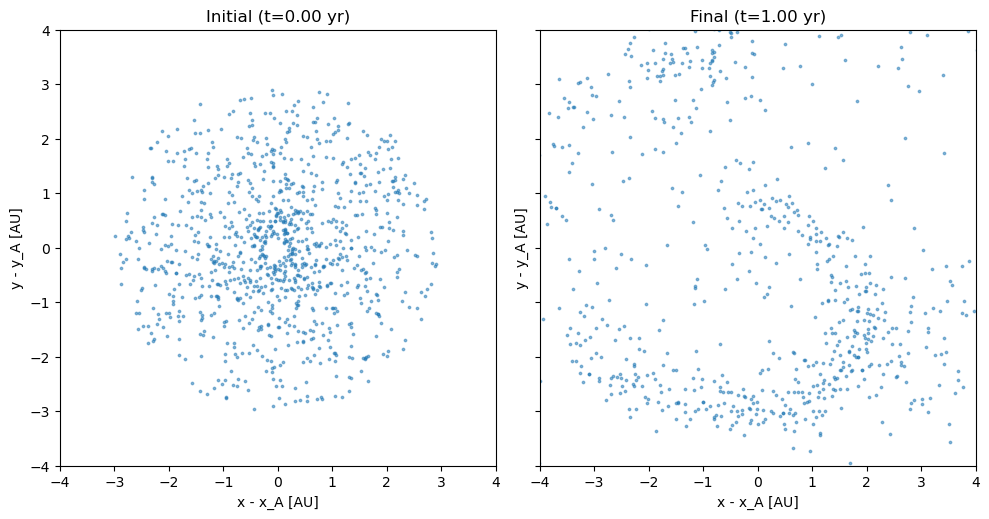

In [12]:
# Time series: gas depletion, embryo growth and disk radial evolution.
t = np.array([h['t'] for h in history])
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].plot(t, [h['embryo_mass'] for h in history])
axes[0].set(ylabel='Embryo mass [Earth masses]', xlabel='Time [yr]')
axes[1].plot(t, [h['mdisk'] for h in history])
axes[1].set(ylabel='Remaining gas [solar masses]', xlabel='Time [yr]')
for k in ('r10', 'r50', 'r90'):
    axes[2].plot(t, [h[k] for h in history], label=k)
axes[2].set(ylabel='Disk mass-percentile radius [AU]', xlabel='Time [yr]')
axes[2].legend()
for ax in axes: ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Initial and final star-centric disk morphology.
fig, axs = plt.subplots(1, 2, figsize=(10, 5), sharex=True, sharey=True)
for ax, h, title in zip(axs, [history[0], history[-1]], ['Initial', 'Final']):
    ax.scatter(h['x'], h['y'], s=3, alpha=0.5)
    ax.set(title=f"{title} (t={h['t']:.2f} yr)", xlabel='x - x_A [AU]', ylabel='y - y_A [AU]')
    ax.set_aspect('equal')
    ax.set_xlim(-4, 4)
    ax.set_ylim(-4, 4)
plt.tight_layout()
plt.show()


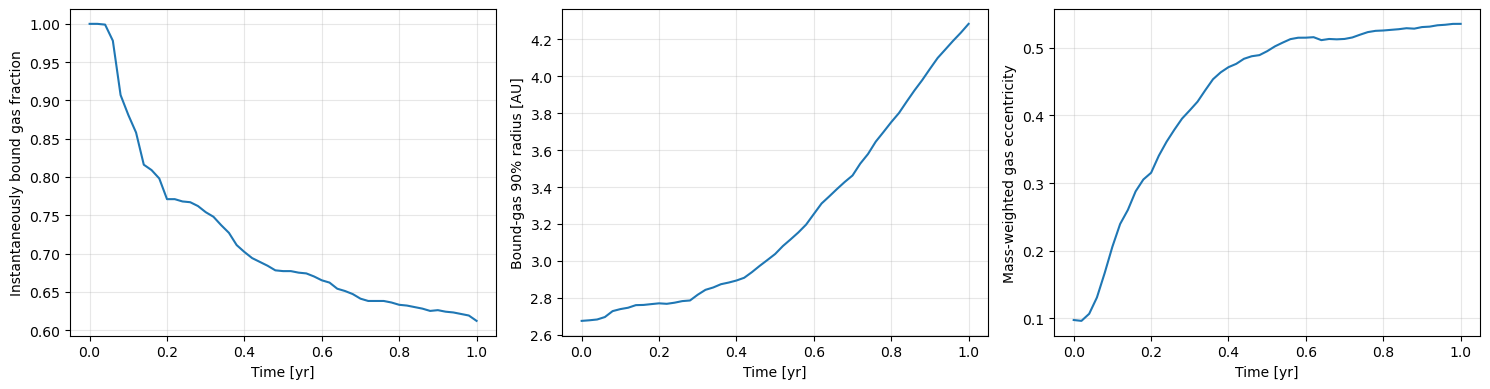

In [13]:
# Disk-survival diagnostics (embryo retained in all integrations).
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, key, ylabel in zip(axes,
    ['bound_fraction', 'r90_bound', 'disk_eccentricity'],
    ['Instantaneously bound gas fraction', 'Bound-gas 90% radius [AU]',
     'Mass-weighted gas eccentricity']):
    ax.plot(t, [h[key] for h in history])
    ax.set(xlabel='Time [yr]', ylabel=ylabel)
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()


### Limitations

- Fi evolves pressure, viscosity and gas self-gravity; the accretion rate is an **external subgrid approximation** based on Fi fields, not resolved gas capture.
- With only 1,000 SPH particles the embryo's Hill sphere is far below the gas sampling scale. The printed `kernel` radius quantifies this limitation. A Hill-limited rate does not mean the Hill sphere is resolved.
- The rate assumes an ideal-gas sound speed from Fi's internal energy and gamma. It does not model cooling, radiative feedback, or a circumplanetary disk.

In [14]:
bridge.stop()
